# Visualisasi — Audio (bentuk gelombang, spektrogram, MFCC, perbandingan kelas)
**Kapan dipakai:** "seperti apa suaranya? frekuensi apa yang dominan? apakah kelas bisa
dibedakan dari suaranya? di detik berapa kejadian terjadi?"

**Isi:** waveform, spektrogram, mel-spektrogram, MFCC, perbandingan mel antar kelas, MFCC
rata-rata per kelas, energi per kelas, anotasi event pada waveform, mel interaktif plotly.
Semua gambar disimpan di folder notebook.

**Data demo:** Speech Commands mini (8 kata, 16 kHz, 1 detik) dan klip event beranotasi.

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/audio"   # GANTI saat lomba
CLIP_FOLDER = f"{DATA_FOLDER}/classification/speech_commands_mini"
TRAIN_CSV = f"{CLIP_FOLDER}/train.csv"
EVENT_FOLDER = f"{DATA_FOLDER}/event"
EVENT_CSV = f"{EVENT_FOLDER}/anotasi.csv"

PATH_COL = "path"
LABEL_COL = "label"
EXAMPLE_LABEL = "yes"   # kelas contoh untuk grafik 1-4
SAMPLE_RATE = 16000     # Hz
N_MELS = 64
N_MFCC = 13
HOP = 160               # geser 160 sampel = 10 ms per kolom spektrogram
CLIPS_PER_CLASS = 40    # jumlah klip per kelas untuk statistik

## Gaya grafik (sama di semua notebook visualisasi)
Font besar supaya terbaca di slide, palet tetap, garis tepi atas/kanan dimatikan.

In [3]:
PALETTE = ["#2E6FB7", "#F28E2B", "#3BA272", "#D1495B", "#7B5EA7", "#9AA0A6"]
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = PALETTE
plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 100, "savefig.dpi": 200,
    "font.size": 14, "axes.titlesize": 18, "axes.titleweight": "bold", "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
sns.set_palette(PALETTE)

## Baca data + fungsi baca klip

In [4]:
train = pd.read_csv(TRAIN_CSV)
classes = sorted(train[LABEL_COL].unique())


def load_clip(path):
    # baca satu klip, panjang disamakan tepat 1 detik (dipotong / ditambah nol)
    wave, _ = librosa.load(f"{CLIP_FOLDER}/{path}", sr=SAMPLE_RATE)
    wave = np.pad(wave, (0, SAMPLE_RATE))
    return wave[:SAMPLE_RATE]


example_path = train[train[LABEL_COL] == EXAMPLE_LABEL].iloc[0][PATH_COL]
wave = load_clip(example_path)
print(train.shape, classes, "| contoh:", example_path, "| panjang:", len(wave))

(1200, 3) ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes'] | contoh: train/yes/d430b3cc_nohash_1.wav | panjang: 16000


## 1. Waveform (bentuk gelombang)
**Kapan dipakai:** langkah pertama, memeriksa panjang, kekerasan, dan bagian hening/clipping.
**Cara baca:** sumbu x = waktu, y = amplitudo (-1 sampai 1). Gelombang rapat dan tinggi = suara
keras, datar = hening, terpotong rata di +-1 = clipping (rekaman terlalu keras).

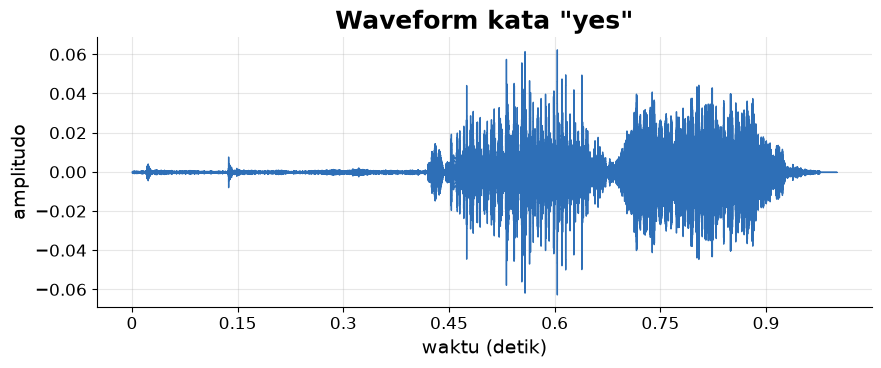

In [5]:
plt.figure(figsize=(10, 3.5))
librosa.display.waveshow(wave, sr=SAMPLE_RATE, color=BLUE)
plt.title(f'Waveform kata "{EXAMPLE_LABEL}"')
plt.xlabel("waktu (detik)")
plt.ylabel("amplitudo")
plt.savefig("audio_waveform.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Spektrogram (STFT)
**Kapan dipakai:** melihat frekuensi apa yang ada di tiap waktu (waveform tak menunjukkan ini).
**Cara baca:** sumbu x = waktu, y = frekuensi (Hz), warna = kekuatan (dB, terang = kuat).
Garis horizontal terang = nada/harmonik, blok terang vertikal = ledakan (konsonan).

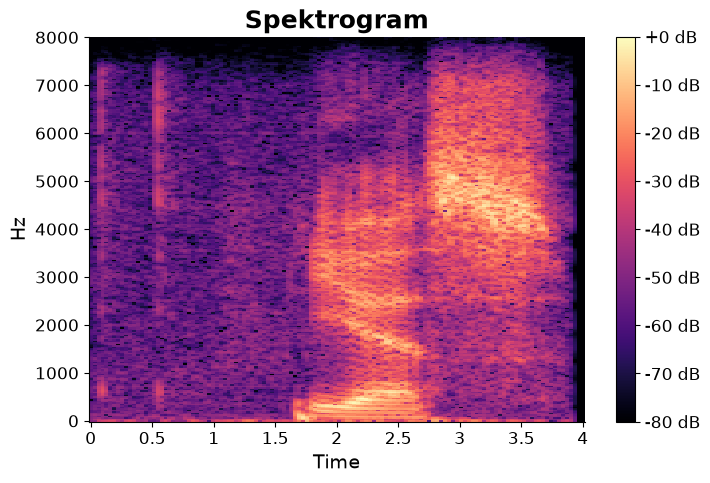

In [6]:
magnitude = np.abs(librosa.stft(wave, n_fft=512))
stft_db = librosa.amplitude_to_db(magnitude, ref=np.max)
image = librosa.display.specshow(stft_db, sr=SAMPLE_RATE, x_axis="time", y_axis="hz",
                                 cmap="magma")
plt.colorbar(image, format="%+2.0f dB")
plt.title("Spektrogram")
plt.savefig("audio_spektrogram.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Mel-spektrogram
**Kapan dipakai:** masukan standar model audio (CNN, AST). Skala frekuensi mengikuti
pendengaran manusia. **Cara baca:** seperti spektrogram, tapi frekuensi rendah lebih
diperbesar. Ini yang dipakai sebagai "gambar" suara.

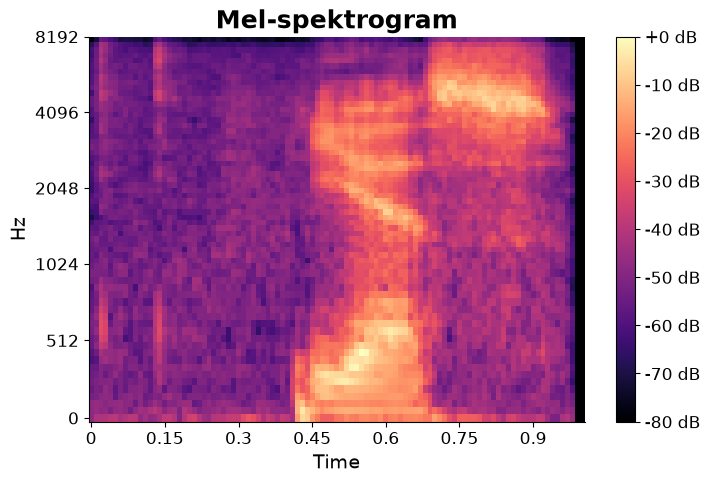

In [7]:
mel = librosa.feature.melspectrogram(y=wave, sr=SAMPLE_RATE, n_fft=512, hop_length=HOP,
                                     n_mels=N_MELS)
mel_db = librosa.power_to_db(mel, ref=np.max)
image = librosa.display.specshow(mel_db, sr=SAMPLE_RATE, hop_length=HOP, x_axis="time",
                                 y_axis="mel", cmap="magma")
plt.colorbar(image, format="%+2.0f dB")
plt.title("Mel-spektrogram")
plt.savefig("audio_mel.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. MFCC
**Kapan dipakai:** fitur ringkas untuk model klasik (SVM, boosting) atau pembeda penutur.
**Cara baca:** baris = koefisien (baris 0 = energi keseluruhan, baris atas = bentuk kasar
spektrum, baris bawah = detail halus), kolom = waktu. Warna merah/biru = nilai tinggi/rendah.

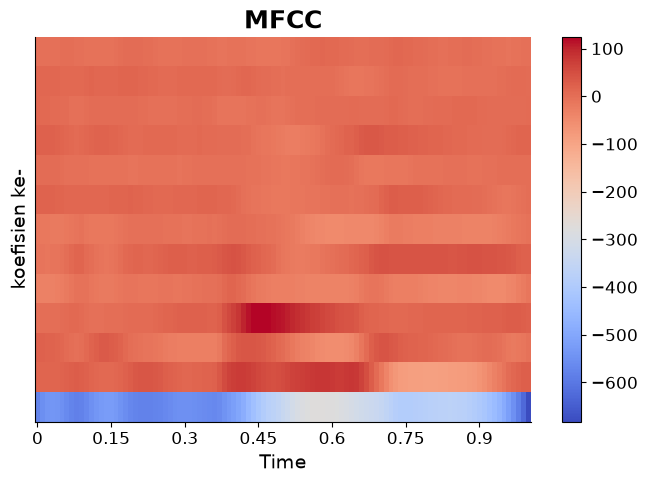

In [8]:
mfcc = librosa.feature.mfcc(y=wave, sr=SAMPLE_RATE, n_mfcc=N_MFCC, hop_length=HOP)
image = librosa.display.specshow(mfcc, sr=SAMPLE_RATE, hop_length=HOP, x_axis="time",
                                 cmap="coolwarm")
plt.colorbar(image)
plt.title("MFCC")
plt.ylabel("koefisien ke-")
plt.savefig("audio_mfcc.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Perbandingan mel-spektrogram antar kelas
**Kapan dipakai:** menilai apakah kelas bisa dibedakan secara visual (dan layak untuk CNN).
**Cara baca:** tiap panel = satu contoh per kelas. Pola warna yang khas per kelas = mudah
dibedakan. Kalau semua mirip, model akan kesulitan.

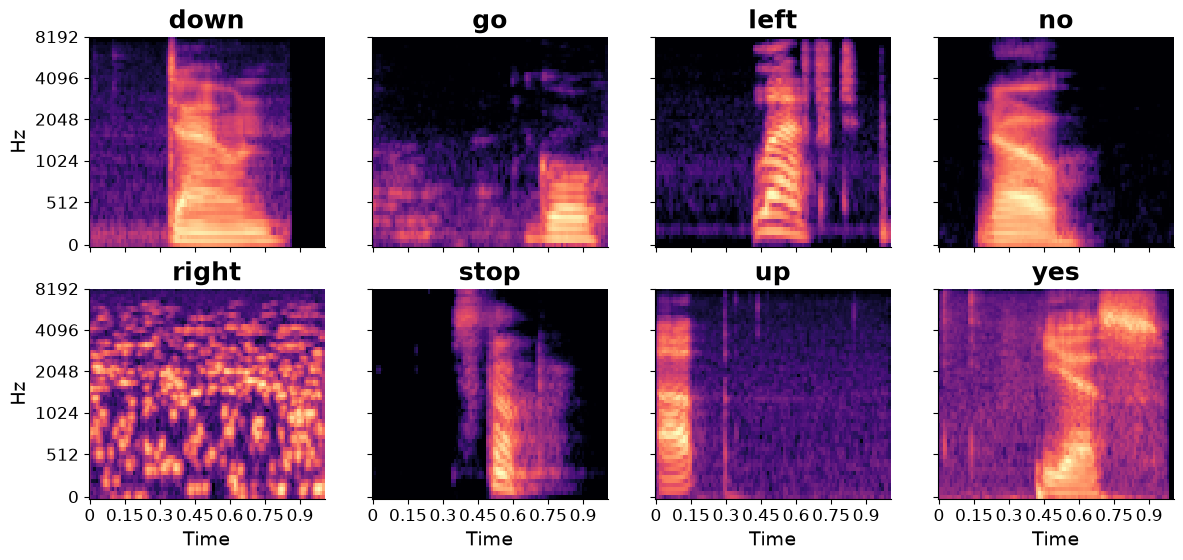

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, name in zip(axes.ravel(), classes):
    first_path = train[train[LABEL_COL] == name].iloc[0][PATH_COL]
    clip = load_clip(first_path)
    class_mel = librosa.feature.melspectrogram(y=clip, sr=SAMPLE_RATE, n_fft=512, hop_length=HOP,
                                               n_mels=N_MELS)
    class_mel_db = librosa.power_to_db(class_mel, ref=np.max)
    librosa.display.specshow(class_mel_db, sr=SAMPLE_RATE, hop_length=HOP, x_axis="time",
                             y_axis="mel", cmap="magma", ax=ax)
    ax.set_title(name)
    ax.label_outer()
plt.savefig("audio_banding_kelas_mel.png", dpi=200, bbox_inches="tight")
plt.show()

## Statistik fitur per kelas (bahan grafik 6 dan 7)
Tiap klip: energi RMS + rata-rata tiap koefisien MFCC sepanjang waktu.

In [10]:
column_names = ["kelas", "energi_rms"]
for i in range(N_MFCC):
    column_names.append(f"mfcc{i}")

rows = []
for name in classes:
    class_paths = train[train[LABEL_COL] == name][PATH_COL]
    for path in class_paths.head(CLIPS_PER_CLASS):
        clip = load_clip(path)
        clip_mfcc = librosa.feature.mfcc(y=clip, sr=SAMPLE_RATE, n_mfcc=N_MFCC)
        rms = np.sqrt(np.mean(clip ** 2))
        rows.append([name, rms] + list(clip_mfcc.mean(axis=1)))
features = pd.DataFrame(rows, columns=column_names)
features.head(3)

,kelas,energi_rms,mfcc0,mfcc1,mfcc2,mfcc3,mfcc4,mfcc5,mfcc6,mfcc7,mfcc8,mfcc9,mfcc10,mfcc11,mfcc12
0,down,0.041980,-412.542542,97.834702,-22.216770,34.320343,5.692323,13.542628,-8.751049,3.070155,-2.371664,-0.838830,-7.115119,2.335840,-4.579938
1,down,0.042199,-528.336182,124.552643,20.958935,-11.650232,-18.732597,1.115649,18.118744,1.769137,-5.114620,4.462685,-1.190104,1.686668,2.688555
2,down,0.020599,-557.694092,121.038162,-8.783193,9.977487,3.060106,8.512503,-8.869994,3.988265,4.199600,3.727943,-7.126091,-4.843371,-8.357499


## 6. MFCC rata-rata per kelas
**Kapan dipakai:** ringkasan numerik perbedaan kelas, cek fitur MFCC berguna untuk klasifikasi.
**Cara baca:** tiap baris = kelas, tiap kolom = koefisien MFCC (dibakukan per kolom). Baris yang
pola warnanya berbeda dari yang lain = mudah dikenali, baris yang mirip = sering tertukar.

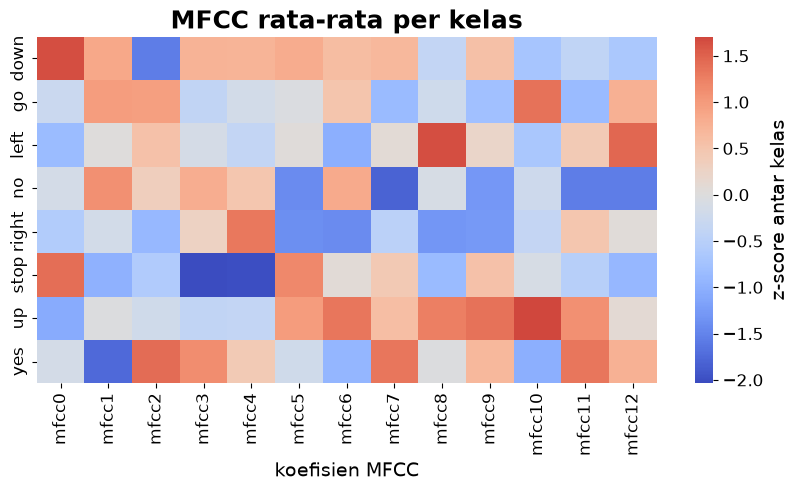

In [11]:
class_mean = features.groupby("kelas").mean()
class_mean = class_mean.drop(columns="energi_rms")
standardized = (class_mean - class_mean.mean()) / class_mean.std()
plt.figure(figsize=(10, 4.5))
sns.heatmap(standardized, cmap="coolwarm", center=0, cbar_kws={"label": "z-score antar kelas"})
plt.title("MFCC rata-rata per kelas")
plt.xlabel("koefisien MFCC")
plt.ylabel("")
plt.grid(False)
plt.savefig("audio_mfcc_per_kelas.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Energi (kekerasan) per kelas
**Kapan dipakai:** memeriksa apakah volume rekaman berbeda antar kelas (bisa jadi jalan pintas
yang menyesatkan model) atau antar perekam. **Cara baca:** kotak = sebaran RMS tiap kelas.
Perbedaan besar antar kelas = perlu normalisasi volume.

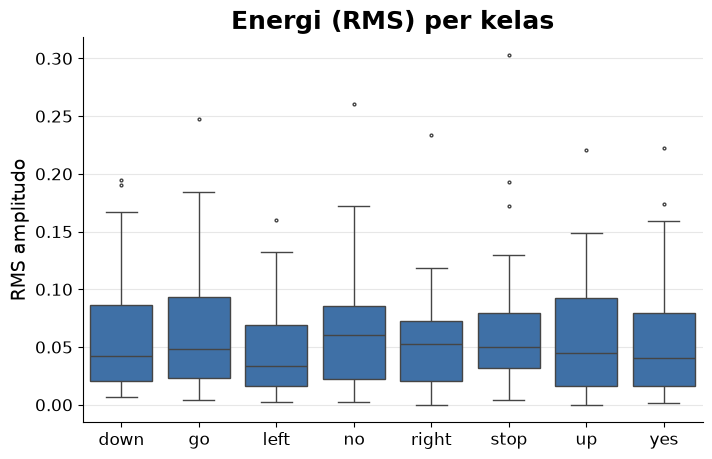

In [12]:
sns.boxplot(data=features, x="kelas", y="energi_rms", color=BLUE, fliersize=2)
plt.title("Energi (RMS) per kelas")
plt.xlabel("")
plt.ylabel("RMS amplitudo")
plt.savefig("audio_energi_per_kelas.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Anotasi event pada waveform
**Kapan dipakai:** deteksi event suara, memeriksa label waktu (onset-offset) sudah pas dengan
suaranya. **Cara baca:** blok berwarna = rentang event dari file anotasi, diberi nama label.
Blok yang tidak menutup bagian suara = anotasi salah waktu.

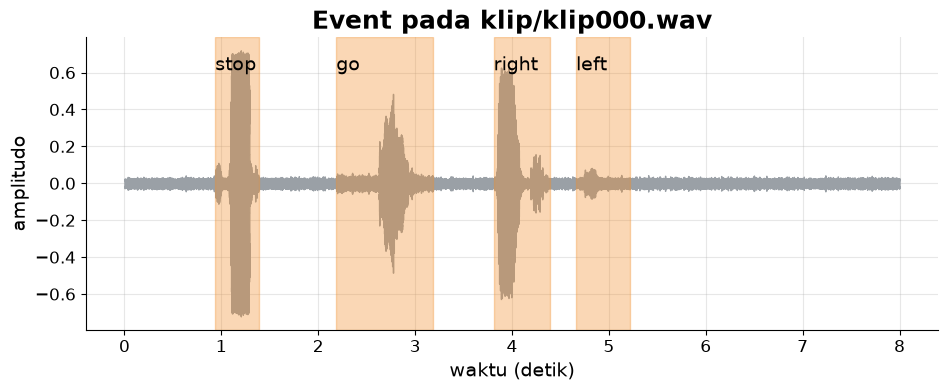

In [13]:
events = pd.read_csv(EVENT_CSV)
event_clip = events[PATH_COL].iloc[0]
event_wave, _ = librosa.load(f"{EVENT_FOLDER}/{event_clip}", sr=SAMPLE_RATE)
clip_events = events[events[PATH_COL] == event_clip]
text_height = 0.85 * np.abs(event_wave).max()

plt.figure(figsize=(11, 3.8))
librosa.display.waveshow(event_wave, sr=SAMPLE_RATE, color=GREY)
for onset, offset, label in zip(clip_events["onset"], clip_events["offset"],
                                clip_events[LABEL_COL]):
    plt.axvspan(onset, offset, color=ORANGE, alpha=0.35)
    plt.text(onset, text_height, label, fontsize=14)
plt.title(f"Event pada {event_clip}")
plt.xlabel("waktu (detik)")
plt.ylabel("amplitudo")
plt.savefig("audio_event_waveform.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Mel-spektrogram interaktif (plotly)
**Kapan dipakai:** memeriksa detail waktu/frekuensi saat analisis atau demo.
**Cara baca:** arahkan kursor untuk melihat waktu, frekuensi mel, dan dB. Seret untuk zoom.

In [14]:
fig = px.imshow(mel_db, origin="lower", aspect="auto", color_continuous_scale="Magma",
                labels={"x": "frame waktu", "y": "band mel", "color": "dB"},
                title="Mel-spektrogram (interaktif)")
fig.write_html("audio_mel_interaktif.html", include_plotlyjs=True)
fig.show()